# Quanto o pneu "cai" por volta?

## Degradação de pneus na Fórmula 1 (GP de Barcelona 2026): abordagem bayesiana *vs.* frequentista

*Trabalho final — Inferência Bayesiana* · **Aluno(a):** Cesar Eustaquio da Fonseca Filho · **Data:** 26/11/2026

> **Resumo.** Com as 956 voltas válidas do GP de Barcelona 2026, estimamos quantos segundos cada composto de pneu perde por volta, descontando o efeito do combustível, do piloto e do carro. O modelo é uma regressão linear normal, estimada por Máxima Verossimilhança e pela abordagem bayesiana com priori conjugada Normal–Gama-Inversa, em dois cenários: vaga e informativa (construída a partir da corrida de 2025). A posteriori é obtida de forma exata e por um amostrador de Gibbs. Resultado principal: em 2026 o pneu médio perdeu **≈ 0,18 s por volta**, cerca de **2,5 vezes** o valor de 2025 (o macio, 0,21; o duro, 0,14). Por isso a priori informativa baseada em 2025 acabou atrapalhando.

---

## 1. Problema e dados

Na F1 todos usam pneus Pirelli, em três compostos de pista seca: **macio**, **médio** e **duro**. A cada volta o pneu se desgasta e o carro fica mais lento (**degradação**); ao mesmo tempo o carro queima combustível, fica mais leve e mais rápido. Saber quantos segundos o pneu perde por volta é a base da estratégia de pit stop. Em 2026 o regulamento mudou (motor 50% elétrico, carros mais leves e pneus mais estreitos), então a pergunta é: **quanto cada pneu degrada na nova era?**

Usamos o GP de Barcelona (circuito de alto desgaste) de **2026** como dados e o de **2025** como conhecimento prévio. Os dados vêm da API pública [OpenF1](https://openf1.org), com cache local em `dados/openf1/`.

In [1]:
import json, time, hashlib, pathlib, warnings
from dataclasses import dataclass
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, requests
from scipy import stats, special, optimize
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence
import arviz as az
warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = pathlib.Path.cwd()
PASTA_DADOS = RAIZ / "dados" / "openf1"; PASTA_DADOS.mkdir(parents=True, exist_ok=True)
PASTA_FIG = RAIZ / "figuras"; PASTA_FIG.mkdir(exist_ok=True)
SEMENTE = 2026                                     # semente fixa: resultados reproduzíveis

# padrão visual dos gráficos
SUPERFICIE, TINTA, TINTA2 = "#fcfcfb", "#0b0b0b", "#52514e"
mpl.rcParams.update({"figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 13, "axes.titlesize": 14, "legend.fontsize": 11, "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "legend.frameon": False})
COR = {"freq": "#52514e", "vaga": "#2a78d6", "info": "#eb6834", "priori": "#1baf7a"}
NOME_MET = {"freq": "Frequentista (EMV)", "vaga": "Bayes — priori vaga", "info": "Bayes — priori informativa",
            "priori": "Priori informativa (2025)"}
COR_COMP = {"SOFT": "#e34948", "MEDIUM": "#eda100", "HARD": "#8f8e88"}
NOME_COMP = {"SOFT": "Macio", "MEDIUM": "Médio", "HARD": "Duro"}
salvar = lambda fig, nome: fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight")

In [2]:
def openf1(endpoint, **filtros):
    """Consulta a API OpenF1, guardando cada resposta em disco (na 2ª vez lê do cache)."""
    chave = endpoint + "?" + "&".join(f"{k}={filtros[k]}" for k in sorted(filtros))
    arq = PASTA_DADOS / f"{endpoint}_{hashlib.md5(chave.encode()).hexdigest()[:12]}.json"
    if not arq.exists():
        r = requests.get(f"https://api.openf1.org/v1/{endpoint}", params=filtros, timeout=60)
        r.raise_for_status()
        arq.write_text(r.text, encoding="utf-8")
        time.sleep(0.4)
    return pd.DataFrame(json.loads(arq.read_text(encoding="utf-8")))

def montar_tabela(chave):
    """Uma linha por volta de cada piloto, com composto, idade do pneu e marcações de voltas atípicas."""
    voltas, stints = openf1("laps", session_key=chave), openf1("stints", session_key=chave)
    pilotos, direcao = openf1("drivers", session_key=chave), openf1("race_control", session_key=chave)
    # conferência: cada stint (menos o 1º) tem de começar numa volta de saída do box
    for drv, g in stints.sort_values("stint_number").groupby("driver_number"):
        saidas = sorted(voltas[(voltas.driver_number == drv) & (voltas.is_pit_out_lap == True)].lap_number)
        if len(saidas) == len(g) - 1 and list(g.lap_start.iloc[1:]) != saidas:
            print(f"  corrigido: piloto {drv}, stints começavam em {list(g.lap_start.iloc[1:])}, box em {saidas}")
            stints.loc[g.index[1:], "lap_start"] = saidas
            stints.loc[g.index[:-1], "lap_end"] = [v - 1 for v in saidas]
    d = (voltas.merge(pilotos[["driver_number", "name_acronym", "team_name"]], on="driver_number")
               .merge(stints[["driver_number", "stint_number", "lap_start", "lap_end", "compound", "tyre_age_at_start"]],
                      on="driver_number"))
    d = d[(d.lap_number >= d.lap_start) & (d.lap_number <= d.lap_end)].copy()     # cada volta no seu stint
    ultimo = d.driver_number.map(stints.groupby("driver_number").stint_number.max())
    neutras, inicio = set(), None                                                   # voltas sob SC/VSC (+1)
    for volta, msg in zip(direcao.lap_number, direcao.message.fillna("").str.upper()):
        if "SAFETY CAR DEPLOYED" in msg or "VSC DEPLOYED" in msg:
            inicio = volta
        elif inicio is not None and ("IN THIS LAP" in msg or "ENDING" in msg):
            neutras |= set(range(int(inicio), int(volta) + 2)); inicio = None
    return pd.DataFrame({
        "piloto": d.name_acronym, "equipe": d.team_name, "volta": d.lap_number.astype(int),
        "stint": d.stint_number.astype(int), "composto": d.compound.str.upper(), "tempo": d.lap_duration,
        "idade_pneu": (d.tyre_age_at_start.fillna(0) + d.lap_number - d.lap_start).astype(int),
        "descartar": (d.lap_number == 1) | d.is_pit_out_lap.fillna(False).astype(bool)          # largada, saída do box
                     | ((d.lap_number == d.lap_end) & (d.stint_number < ultimo))              # entrada no box
                     | d.lap_number.isin(neutras) | d.lap_duration.isna()                     # SC/VSC, sem tempo
                     | ~d.compound.str.upper().isin(["SOFT", "MEDIUM", "HARD"]),               # pneu de chuva
    })

sessoes = pd.concat([openf1("sessions", year=a, session_name="Race") for a in (2025, 2026)])
CHAVE = dict(sessoes[sessoes.circuit_short_name == "Catalunya"][["year", "session_key"]].values)

limpo, funil = {}, {}
for ano in (2025, 2026):
    tab = montar_tabela(CHAVE[ano])
    t = tab[~tab.descartar]
    t = t[t.tempo <= 1.07 * t.groupby("piloto").tempo.transform("min")]   # problemas/danos (regra dos 107%)
    limpo[ano] = t.reset_index(drop=True)
    funil[ano] = {"voltas registradas": len(tab), "após descartes": int((~tab.descartar).sum()), "após regra dos 107%": len(t)}
pd.DataFrame(funil)

  corrigido: piloto 87, stints começavam em [19, 29], box em [19, 40]


,2025,2026
voltas registradas,1202,1234
após descartes,980,1024
após regra dos 107%,956,973


Retiramos voltas que não medem desgaste: a largada, as voltas de entrada e saída do box, as voltas sob safety car e as que passam de 107% da melhor volta do piloto. Também conferimos os *stints* da OpenF1 contra as voltas de saída do box. Num caso (Bearman, 2026) a API marcava a troca de pneus 11 voltas antes da parada real, e o registro foi corrigido.

| Símbolo | Variável | Unidade | Significado |
|---|---|---|---|
| $y_i$ | tempo de volta | s | **resposta** |
| $L_i$ | idade do pneu | voltas | voltas já feitas com o jogo de pneus → **degradação** |
| $T_i$ | volta da corrida | voltas | combustível queimado + pista emborrachada |
| $S_i, H_i$ | pneu macio / duro | 0/1 | o médio é a referência |
| $P_{ij}$, $E_{ik}$ | piloto $j$ / equipe $k$ | −1/0/1 | ritmo de cada piloto e degradação de cada carro |

In [3]:
(limpo[2026].groupby("composto")
    .agg(voltas=("tempo", "size"), pilotos=("piloto", "nunique"), tempo_medio=("tempo", "mean"), tempo_dp=("tempo", "std"),
         idade_media=("idade_pneu", "mean"), idade_max=("idade_pneu", "max"), volta_media=("volta", "mean"))
    .rename(index=NOME_COMP).round(2))

,voltas,pilotos,tempo_medio,tempo_dp,idade_media,idade_max,volta_media
composto,,,,,,,
Duro,617,21,83.58,1.67,10.93,26,34.56
Médio,246,18,84.29,1.85,8.09,22,19.85
Macio,110,11,84.46,1.44,7.08,19,21.46


O gráfico abaixo mostra o "dente de serra": o tempo sobe dentro de cada stint (desgaste) e cai no pit stop (pneu novo). Como **o contador do pneu zera no box e o da corrida não**, conseguimos separar o desgaste do efeito do combustível.

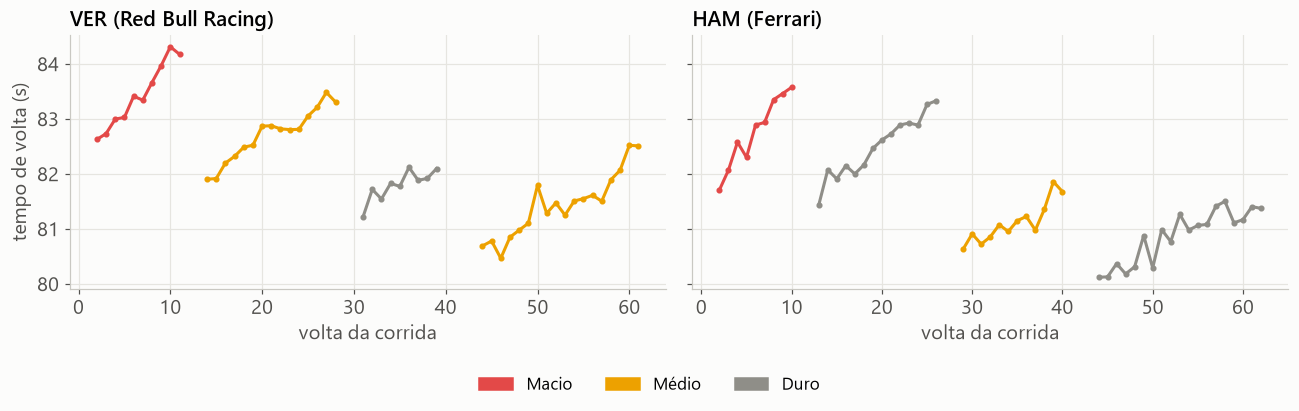

In [4]:
t26 = limpo[2026]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, piloto in zip(axes, ["VER", "HAM"]):   # dois pilotos que usaram os três compostos
    dp = t26[t26.piloto == piloto]
    for (_, comp), g in dp.groupby(["stint", "composto"]):
        g = g.set_index("volta").reindex(range(g.volta.min(), g.volta.max() + 1))
        ax.plot(g.index, g.tempo, color=COR_COMP[comp], lw=2, marker="o", ms=3)
    ax.set_title(f"{piloto} ({dp.equipe.iloc[0]})"); ax.set_xlabel("volta da corrida")
axes[0].set_ylabel("tempo de volta (s)")
fig.legend(handles=[mpl.patches.Patch(color=COR_COMP[c], label=NOME_COMP[c]) for c in COR_COMP],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.05, 1, 1)); salvar(fig, "fig02_dente_de_serra"); plt.show()

---

## 2. Etapa A — Modelo clássico e Máxima Verossimilhança

$$
y_i=\beta_0+\beta_1L_i+\beta_2S_i+\beta_3H_i+\beta_4L_iS_i+\beta_5L_iH_i+\beta_6T_i+\sum_{j=1}^{J-1}\alpha_jP_{ij}+\sum_{k=1}^{K-1}\gamma_kL_iE_{ik}+\varepsilon_i,\qquad \varepsilon_i\overset{\text{iid}}{\sim}\mathcal N(0,\sigma^2).
$$

$\beta_1$ é a degradação do **médio** (s/volta); $\beta_1+\beta_4$ e $\beta_1+\beta_5$ as do **macio** e do **duro**; $\beta_2,\beta_3$ a diferença de ritmo do pneu novo; $\beta_6$ o ganho por volta de corrida; $\alpha_j$ o ritmo de cada piloto e $\gamma_k$ a degradação extra de cada carro, ambos medidos em relação à média do grid (codificação por desvio). Em forma matricial, $\mathbf y=X\beta+\boldsymbol\varepsilon$, com $p=38$ colunas em $X$ e $\theta=(\beta,\sigma^2)$.

**Verossimilhança e EMV.**

$$
p(\mathbf y\mid X,\beta,\sigma^2)=(2\pi\sigma^2)^{-n/2}\exp\Big\{-\tfrac{1}{2\sigma^2}(\mathbf y-X\beta)^\top(\mathbf y-X\beta)\Big\},\qquad
\hat\beta=(X^\top X)^{-1}X^\top\mathbf y,\quad \hat\sigma^2=\tfrac1n\lVert\mathbf y-X\hat\beta\rVert^2 .
$$

A **informação de Fisher observada** no EMV é $\mathcal J(\hat\theta)=\operatorname{diag}\big(X^\top X/\hat\sigma^2,\ n/(2\hat\sigma^4)\big)$, logo $\widehat{\operatorname{Var}}(\hat\beta)=\hat\sigma^2(X^\top X)^{-1}$ e o IC de 95% é $\hat\beta_j\pm1{,}96\,\widehat{\text{ep}}(\hat\beta_j)$.

In [5]:
FISICOS = ["deg_medio", "delta_macio", "delta_duro", "deg_extra_macio", "deg_extra_duro", "combustivel"]

def desvio(valores, niveis):
    """Codificação por desvio: nível k -> 1 na coluna k; último nível -> -1; fora da lista -> 0."""
    v = np.asarray(valores); M = np.zeros((len(v), len(niveis) - 1))
    for k, nv in enumerate(niveis[:-1]):
        M[:, k] = (v == nv)
    M[v == niveis[-1], :] = -1.0
    return M

def matriz_X(t, modelo="M2", pilotos=None, equipes=None):
    """Matriz de delineamento. M0: degradação única | M1: por composto | M2: por composto e por carro."""
    L, T = t.idade_pneu.to_numpy(float), t.volta.to_numpy(float)
    S, H = (t.composto == "SOFT").to_numpy(float), (t.composto == "HARD").to_numpy(float)
    col = {"intercepto": np.ones(len(t)), "deg_medio": L, "delta_macio": S, "delta_duro": H}
    if modelo in ("M1", "M2"):
        col["deg_extra_macio"], col["deg_extra_duro"] = L * S, L * H
    col["combustivel"] = T
    P = desvio(t.piloto, pilotos)
    col.update({f"ritmo[{pl}]": P[:, j] for j, pl in enumerate(pilotos[:-1])})
    if modelo == "M2":
        E = desvio(t.equipe, equipes)
        col.update({f"deg[{eq}]": L * E[:, k] for k, eq in enumerate(equipes[:-1])})
    return np.column_stack(list(col.values())), list(col)

def ajustar_emv(X, y):
    n, p = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    res = y - X @ beta
    s2 = res @ res / n
    cov = np.zeros((p + 1, p + 1))                      # inversa da informação de Fisher observada
    cov[:p, :p], cov[p, p] = s2 * XtX_inv, 2 * s2**2 / n
    loglik = -0.5 * n * np.log(2 * np.pi * s2) - 0.5 * n
    return dict(beta=beta, s2=s2, cov=cov, res=res, n=n, p=p, loglik=loglik, XtX_inv=XtX_inv)

NIVEIS = {a: dict(pilotos=sorted(limpo[a].piloto.unique()), equipes=sorted(limpo[a].equipe.unique())) for a in (2025, 2026)}

# remove voltas com resíduo estudentizado |r| > 3 (tráfego, erro do piloto), uma única vez
dados = {}
for ano in (2025, 2026):
    X, _ = matriz_X(limpo[ano], "M2", **NIVEIS[ano])
    r = OLSInfluence(sm.OLS(limpo[ano].tempo.to_numpy(), X).fit()).resid_studentized_external
    dados[ano] = limpo[ano][np.abs(r) <= 3].reset_index(drop=True)
    print(f"{ano}: {len(dados[ano])} voltas no conjunto final ({(np.abs(r) > 3).sum()} atípicas removidas)")

t26, t25 = dados[2026], dados[2025]
y26, y25 = t26.tempo.to_numpy(), t25.tempo.to_numpy()
X26, nomes26 = matriz_X(t26, "M2", **NIVEIS[2026])
X25, nomes25 = matriz_X(t25, "M2", **NIVEIS[2025])
emv26 = ajustar_emv(X26, y26)

2025: 938 voltas no conjunto final (18 atípicas removidas)


2026: 956 voltas no conjunto final (17 atípicas removidas)


O vetor completo $\hat\theta=(\hat\beta,\hat\sigma^2)$, com erros-padrão da informação de Fisher observada e IC de 95%:

In [6]:
GREGO = {"intercepto": "β̂0", "deg_medio": "β̂1", "delta_macio": "β̂2", "delta_duro": "β̂3",
         "deg_extra_macio": "β̂4", "deg_extra_duro": "β̂5", "combustivel": "β̂6"}
rot = [GREGO.get(n) or n.replace("ritmo[", "α̂[").replace("deg[", "γ̂[") for n in nomes26] + ["σ̂²"]
est, ep = np.r_[emv26["beta"], emv26["s2"]], np.sqrt(np.diag(emv26["cov"]))
pd.DataFrame({"estimativa": est, "erro-padrão": ep, "IC95% inf": est - 1.96 * ep, "IC95% sup": est + 1.96 * ep},
             index=rot).round(3)

,estimativa,erro-padrão,IC95% inf,IC95% sup
β̂0,84.245,0.061,84.126,84.365
β̂1,0.179,0.007,0.165,0.192
β̂2,-0.380,0.116,-0.606,-0.153
β̂3,0.218,0.074,0.073,0.363
β̂4,0.033,0.014,0.007,0.060
β̂5,-0.038,0.008,-0.053,-0.024
β̂6,-0.060,0.001,-0.062,-0.058
α̂[ALB],1.261,0.094,1.077,1.446
α̂[ALO],2.003,0.156,1.696,2.309
α̂[ANT],-1.914,0.098,-2.106,-1.723


As perguntas de engenharia são combinações lineares $\mathbf c^\top\beta$ dos coeficientes, com $\widehat{\text{ep}}=\sqrt{\mathbf c^\top\widehat{\operatorname{Var}}(\hat\beta)\,\mathbf c}$:

In [7]:
QOI = {"Degradação do médio (s por volta)": {"deg_medio": 1},
       "Degradação do macio (s por volta)": {"deg_medio": 1, "deg_extra_macio": 1},
       "Degradação do duro (s por volta)":  {"deg_medio": 1, "deg_extra_duro": 1},
       "Macio novo − médio novo (s)":   {"delta_macio": 1},
       "Duro novo − médio novo (s)":    {"delta_duro": 1},
       "Efeito por volta de corrida (s por volta)": {"combustivel": 1}}

def vetor_c(nomes, termos):
    return np.array([termos.get(n, 0.0) for n in nomes])

def tabela_freq(emv, nomes):
    lin = {}
    for rot, termos in QOI.items():
        c = vetor_c(nomes, termos)
        est, ep = c @ emv["beta"], np.sqrt(c @ emv["cov"][:-1, :-1] @ c)
        lin[rot] = dict(media=est, ep=ep, lo=est - 1.96 * ep, hi=est + 1.96 * ep)
    ep_s2 = np.sqrt(emv["cov"][-1, -1])
    lin["Variância do ruído σ² (s²)"] = dict(media=emv["s2"], ep=ep_s2, lo=emv["s2"] - 1.96 * ep_s2, hi=emv["s2"] + 1.96 * ep_s2)
    return pd.DataFrame(lin).T

freq = tabela_freq(emv26, nomes26)
print(f"n = {emv26['n']} voltas, p = {emv26['p']} coeficientes")
freq.rename(columns={"media": "EMV", "ep": "erro-padrão", "lo": "IC95% inf", "hi": "IC95% sup"}).round(4)

n = 956 voltas, p = 38 coeficientes


,EMV,erro-padrão,IC95% inf,IC95% sup
Degradação do médio (s por volta),0.1788,0.0069,0.1652,0.1924
Degradação do macio (s por volta),0.2122,0.0122,0.1883,0.2361
Degradação do duro (s por volta),0.1403,0.0038,0.1328,0.1478
Macio novo − médio novo (s),-0.3796,0.1155,-0.6061,-0.1532
Duro novo − médio novo (s),0.2179,0.0741,0.0727,0.3632
Efeito por volta de corrida (s por volta),-0.0601,0.0012,-0.0624,-0.0578
Variância do ruído σ² (s²),0.2075,0.0095,0.1889,0.2261


**Leitura.** Descontado o combustível, o **macio perde ≈ 0,21 s por volta**, o **médio ≈ 0,18** e o **duro ≈ 0,14**. É a ordem esperada: quanto mais macio o composto, mais aderência (o macio novo é ≈ 0,38 s mais rápido que o médio novo, e o duro novo ≈ 0,22 s mais lento) e mais desgaste. Cada volta de corrida deixa o carro ≈ 0,06 s mais rápido.

**Predição pontual clássica** para *Leclerc (Ferrari), pneu duro com 15 voltas, na volta 55*: $\hat y_{\text{novo}}=\mathbf x_{\text{novo}}^\top\hat\beta$, com intervalo de predição $\hat y_{\text{novo}}\pm t_{n-p;0{,}975}\,s\sqrt{1+\mathbf x_{\text{novo}}^\top(X^\top X)^{-1}\mathbf x_{\text{novo}}}$.

In [8]:
CENARIO = pd.DataFrame({"piloto": ["LEC"], "equipe": ["Ferrari"], "composto": ["HARD"], "idade_pneu": [15], "volta": [55]})
x_novo = matriz_X(CENARIO, "M2", **NIVEIS[2026])[0][0]
n, p = X26.shape
y_hat = x_novo @ emv26["beta"]
s2_nv = emv26["res"] @ emv26["res"] / (n - p)
meia = stats.t.ppf(0.975, n - p) * np.sqrt(s2_nv * (1 + x_novo @ emv26["XtX_inv"] @ x_novo))
pred_freq = dict(media=y_hat, lo=y_hat - meia, hi=y_hat + meia)
print(f"Predição clássica: {y_hat:.3f} s | intervalo de predição 95%: [{y_hat - meia:.3f}; {y_hat + meia:.3f}] s")

Predição clássica: 81.858 s | intervalo de predição 95%: [80.933; 82.783] s


---

## 3. Etapa B — Modelo bayesiano

**Verossimilhança:** a mesma da Etapa A, $p(\mathbf y\mid X,\theta)$ com $\theta=(\beta,\sigma^2)$.

**Priori conjugada Normal–Gama-Inversa** (equivalente à Normal-Gama na precisão $\tau=1/\sigma^2$):

$$
\beta\mid\sigma^2\sim\mathcal N_p(\mathbf m_0,\sigma^2V_0):\ \ p(\beta\mid\sigma^2)=(2\pi\sigma^2)^{-p/2}|V_0|^{-1/2}e^{-\frac{(\beta-\mathbf m_0)^\top V_0^{-1}(\beta-\mathbf m_0)}{2\sigma^2}},
\qquad
\sigma^2\sim\mathcal{GI}(a_0,b_0):\ \ p(\sigma^2)=\frac{b_0^{a_0}}{\Gamma(a_0)}(\sigma^2)^{-(a_0+1)}e^{-b_0/\sigma^2}.
$$

**Cenário (a) — vaga:** $\mathbf m_0=\mathbf 0$, $V_0=10^6I_p$, $a_0=b_0=0{,}01$. Desvio-padrão *a priori* de centenas de segundos: "não sei nada". No limite $V_0^{-1}\to0$, $a_0,b_0\to0$ ela tende à priori imprópria $p(\beta,\sigma^2)\propto(\sigma^2)^{-(p/2+1)}$ (regra de Jeffreys conjunta), cuja posteriori é $\beta\mid\mathbf y\sim t_n\big(\hat\beta,\hat\sigma^2(X^\top X)^{-1}\big)$, ou seja, reproduz os números do EMV.

**Cenário (b) — informativa (corrida de 2025):** usamos uma *power prior* (Ibrahim & Chen, 2000), $p(\theta\mid\mathcal D_{2025})\propto p(\mathcal D_{2025}\mid\theta)^{\alpha_0}\,p_{\text{vaga}}(\theta)$, com **$\alpha_0=0{,}1$**: como o regulamento mudou, a corrida de 2025 vale só 10% de uma corrida nova. Como o modelo de 2025 tem outros pilotos e equipes, a power prior é calculada no modelo de 2025 e dela herdamos só a marginal dos parâmetros físicos e de $\sigma^2$: se a power posterior é $\mathcal{NGI}(\tilde{\mathbf m},\tilde V,\tilde a,\tilde b)$, então $\mathbf m_{0,\text{fís}}=\tilde{\mathbf m}_{\text{fís}}$, $V_{0,\text{fís}}=\tilde V_{\text{fís}}$, $a_0=\tilde a$ e $b_0=\tilde b$. Os efeitos de piloto e de equipe não são herdados de 2025: o grid mudou (a Cadillac estreou, a Sauber virou Audi e 4 dos 22 pilotos não aparecem nos dados de 2025) e, com o regulamento novo, a diferença de ritmo entre os carros também. Para eles usamos conhecimento de domínio: intercepto centrado em 2025 com dp de 3 s, $\alpha_j\sim\mathcal N(0,1^2)$ s e $\gamma_k\sim\mathcal N(0,0{,}05^2)$ s/volta. (Na NGI, dar dp $d$ a um coeficiente significa $V_{0,jj}=d^2/\mathbb E[\sigma^2]$.)

In [9]:
@dataclass
class NGI:
    """beta | s2 ~ N(m, s2 V),  s2 ~ GI(a, b)."""
    m: np.ndarray; V: np.ndarray; a: float; b: float

def atualizar(pr, X, y, peso=1.0):
    """Teorema de Bayes em forma fechada (peso < 1 = power prior)."""
    V0_inv = np.linalg.inv(pr.V)
    Vn = np.linalg.inv(V0_inv + peso * X.T @ X); Vn = (Vn + Vn.T) / 2
    mn = Vn @ (V0_inv @ pr.m + peso * X.T @ y)
    r, d = y - X @ mn, mn - pr.m
    return NGI(mn, Vn, pr.a + peso * len(y) / 2, pr.b + 0.5 * (peso * r @ r + d @ V0_inv @ d))

def priori_vaga(p):
    return NGI(np.zeros(p), 1e6 * np.eye(p), 0.01, 0.01)

def priori_informativa(X25, y25, nomes25, nomes26, alpha0=0.1):
    pot = atualizar(priori_vaga(len(nomes25)), X25, y25, peso=alpha0)       # power prior de 2025
    s2_ref = pot.b / (pot.a - 1)                                           # E[sigma^2] a priori
    m0, V0 = np.zeros(len(nomes26)), np.zeros((len(nomes26), len(nomes26)))
    fis = [n for n in nomes26 if n in FISICOS]
    i26, i25 = [nomes26.index(n) for n in fis], [nomes25.index(n) for n in fis]
    m0[i26], V0[np.ix_(i26, i26)] = pot.m[i25], pot.V[np.ix_(i25, i25)]
    for k, n in enumerate(nomes26):
        if n == "intercepto":
            m0[k], V0[k, k] = pot.m[nomes25.index(n)], 3.0**2 / s2_ref
        elif n.startswith("ritmo["):
            V0[k, k] = 1.0**2 / s2_ref
        elif n.startswith("deg["):
            V0[k, k] = 0.05**2 / s2_ref
    return NGI(m0, V0, pot.a, pot.b)

prioris = {"vaga": priori_vaga(len(nomes26)), "info": priori_informativa(X25, y25, nomes25, nomes26)}
pi = prioris["info"]
dp_pri = np.sqrt(pi.b / (pi.a - 1) * np.diag(pi.V))
print(f"Priori informativa de sigma^2: GI({pi.a:.1f}; {pi.b:.1f})")
pd.DataFrame({"média a priori": pi.m, "dp a priori": dp_pri}, index=nomes26).loc[FISICOS].round(4)

Priori informativa de sigma^2: GI(46.9; 11.2)


,média a priori,dp a priori
deg_medio,0.0725,0.0120
delta_macio,-0.4133,0.2250
delta_duro,-1.5317,4.0506
deg_extra_macio,0.0205,0.0194
deg_extra_duro,0.1717,0.4956
combustivel,-0.0584,0.0031


A corrida de 2025 diz que o médio perdia **≈ 0,07 s por volta**. A incerteza a priori do pneu duro é grande porque em 2025 quase ninguém o usou em Barcelona.

---

## 4. Etapa C — Posteriori e MCMC

**Posteriori exata.** Pelo Teorema de Bayes, $p(\theta\mid\mathbf y,X)\propto p(\mathbf y\mid X,\theta)\,p(\theta)$, e a conjugação dá $\mathcal{NGI}(\mathbf m_n,V_n,a_n,b_n)$:

$$
V_n=(V_0^{-1}+X^\top X)^{-1},\quad \mathbf m_n=V_n(V_0^{-1}\mathbf m_0+X^\top\mathbf y),\quad a_n=a_0+\tfrac n2,\quad b_n=b_0+\tfrac12\big[\lVert\mathbf y-X\mathbf m_n\rVert^2+(\mathbf m_n-\mathbf m_0)^\top V_0^{-1}(\mathbf m_n-\mathbf m_0)\big],
$$

com marginais $\sigma^2\mid\mathbf y\sim\mathcal{GI}(a_n,b_n)$ e $\mathbf c^\top\beta\mid\mathbf y\sim t_{2a_n}\big(\mathbf c^\top\mathbf m_n,\ \tfrac{b_n}{a_n}\mathbf c^\top V_n\mathbf c\big)$.

**Amostrador de Gibbs.** Alterna entre as condicionais completas:

$$
\beta\mid\sigma^2,\mathbf y\sim\mathcal N_p(\mathbf m_n,\sigma^2V_n),\qquad
\sigma^2\mid\beta,\mathbf y\sim\mathcal{GI}\Big(a_0+\tfrac{n+p}2,\ b_0+\tfrac12\big[\lVert\mathbf y-X\beta\rVert^2+(\beta-\mathbf m_0)^\top V_0^{-1}(\beta-\mathbf m_0)\big]\Big).
$$

Rodamos 4 cadeias com valores iniciais dispersos ($\sigma^2\in\{0{,}01;0{,}1;1;10\}$), 6 000 iterações e 1 000 de aquecimento, o que dá 20 000 sorteios por cenário.

In [10]:
def gibbs(X, y, pr, n_iter=6000, aquecimento=1000, cadeias=4, semente=SEMENTE):
    n, p = X.shape
    V0_inv = np.linalg.inv(pr.V)
    Vn = np.linalg.inv(V0_inv + X.T @ X); Vn = (Vn + Vn.T) / 2
    mn = Vn @ (V0_inv @ pr.m + X.T @ y)
    Lc = np.linalg.cholesky(Vn)
    B, S2 = np.empty((cadeias, n_iter, p)), np.empty((cadeias, n_iter))
    for c in range(cadeias):
        g, s2 = np.random.default_rng(semente + c), [0.01, 0.1, 1.0, 10.0][c % 4]
        for it in range(n_iter):
            beta = mn + np.sqrt(s2) * (Lc @ g.standard_normal(p))                              # beta | sigma2, y
            r, d = y - X @ beta, beta - pr.m
            s2 = (pr.b + 0.5 * (r @ r + d @ V0_inv @ d)) / g.gamma(pr.a + (n + p) / 2)        # sigma2 | beta, y
            B[c, it], S2[c, it] = beta, s2
    return B[:, aquecimento:], S2[:, aquecimento:]

post = {k: atualizar(pr, X26, y26) for k, pr in prioris.items()}       # posterioris exatas
mcmc = {k: gibbs(X26, y26, pr) for k, pr in prioris.items()}          # posterioris via Gibbs
amostras = lambda B: {rot: B @ vetor_c(nomes26, termos) for rot, termos in QOI.items()}

**Diagnóstico gráfico** (priori vaga; o cenário informativo é idêntico em comportamento): traço, densidade por cadeia e autocorrelação.

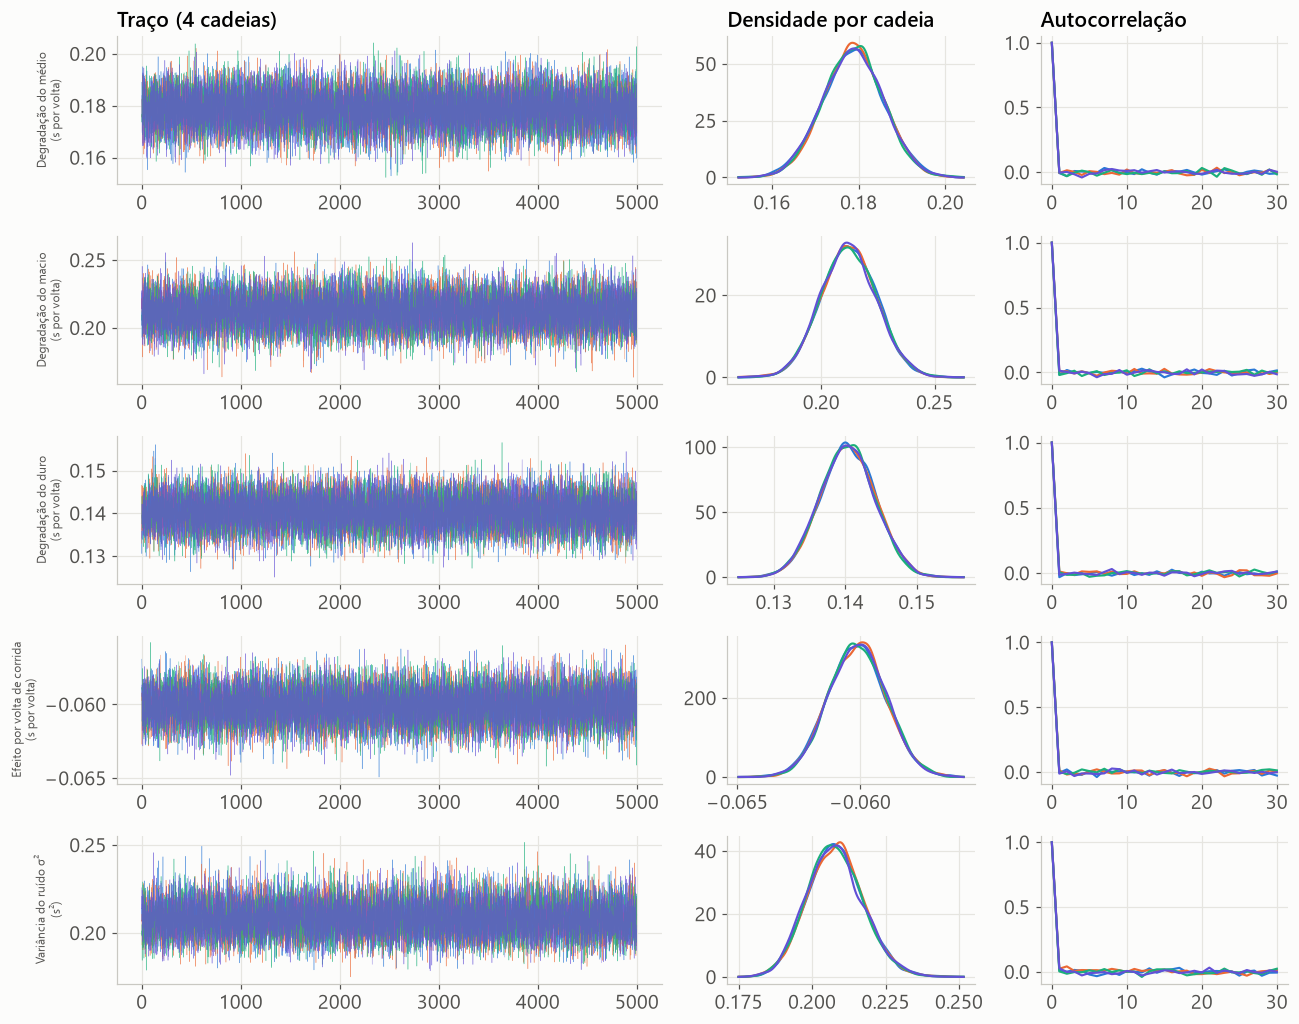

In [11]:
def acf(x, lags=30):
    x = x - x.mean()
    return np.array([1.0] + [(x[:-k] @ x[k:]) / (x @ x) for k in range(1, lags + 1)])

B, S2 = mcmc["vaga"]
q = {k: v for k, v in amostras(B).items() if "Degradação" in k or "Efeito" in k}
q["Variância do ruído σ² (s²)"] = S2
cores = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
fig, axes = plt.subplots(len(q), 3, figsize=(12, 1.9 * len(q)), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
for lin, (rot, x) in enumerate(q.items()):
    grade = np.linspace(x.min(), x.max(), 200)
    for c in range(4):
        axes[lin, 0].plot(x[c], color=cores[c], lw=0.3, alpha=0.7)
        axes[lin, 1].plot(grade, stats.gaussian_kde(x[c])(grade), color=cores[c], lw=1.4)
        axes[lin, 2].plot(acf(x[c]), color=cores[c], lw=1.4)
    axes[lin, 0].set_ylabel(rot.replace(" (", "\n("), fontsize=8)
for ax, tit in zip(axes[0], ["Traço (4 cadeias)", "Densidade por cadeia", "Autocorrelação"]):
    ax.set_title(tit)
fig.tight_layout(); salvar(fig, "fig05_diagnostico_vaga"); plt.show()

**Diagnóstico formal.** Com $M$ cadeias de $N$ sorteios, variância média dentro das cadeias $W$ e variância entre as médias das cadeias $B$:

$$
\hat R=\sqrt{\frac{\frac{N-1}{N}W+\frac{1}{N}B}{W}},\qquad \text{ESS}=\frac{MN}{1+2\sum_{t\ge1}\hat\rho_t},
$$

em que $\hat\rho_t$ é a autocorrelação na defasagem $t$. Usamos a versão normalizada por postos (Vehtari et al., 2021), com os critérios $\hat R<1{,}01$ e ESS > 400, para todos os 38 coeficientes e $\sigma^2$.

In [12]:
diag = {}
for k, (B, S2) in mcmc.items():
    dados_az = {"sigma2": S2, **{n: B[:, :, j] for j, n in enumerate(nomes26)}}
    diag[k] = az.summary(az.from_dict({"posterior": dados_az}), ci_prob=0.95, ci_kind="hdi")
pd.DataFrame({NOME_MET[k]: {"maior R-hat": d.r_hat.astype(float).max(), "menor ESS (bulk)": d.ess_bulk.astype(float).min(),
                            "menor ESS (tail)": d.ess_tail.astype(float).min()} for k, d in diag.items()}).round(4)

,Bayes — priori vaga,Bayes — priori informativa
maior R-hat,1.0005,1.0005
menor ESS (bulk),18762.7647,18764.5295
menor ESS (tail),18532.9623,18652.0756


**Posteriori exata *vs.* MCMC.** Curvas: densidades analíticas ($t$ e Gama-Inversa). Histogramas: sorteios do Gibbs.

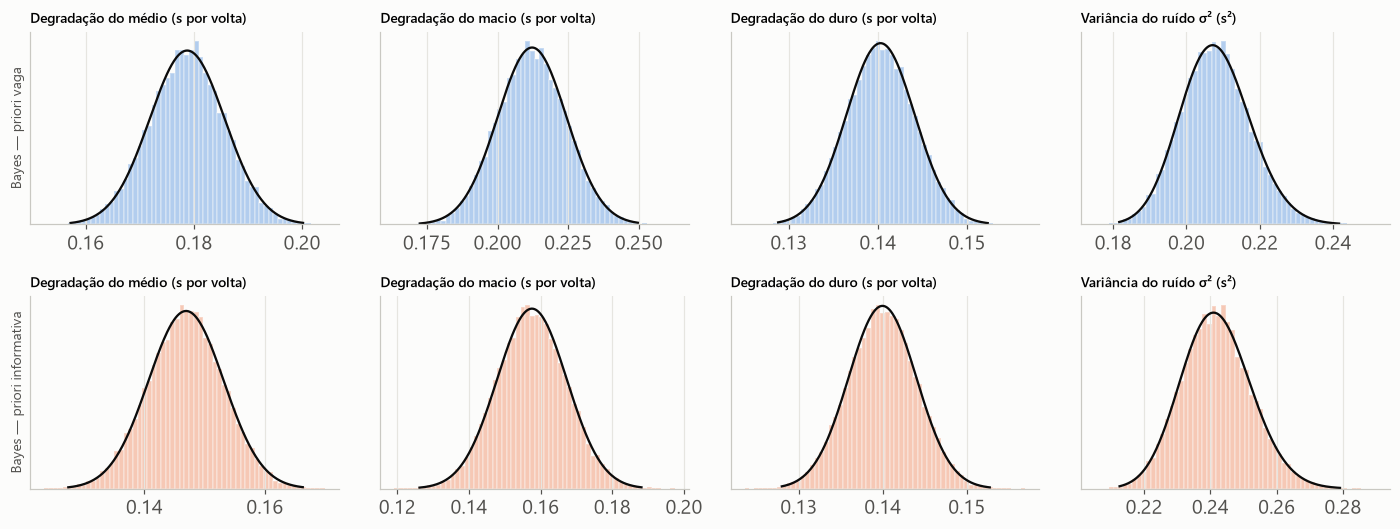

média exata  \
Bayes — priori vaga        Degradação do médio (s por volta)       0.1788   
                           Degradação do macio (s por volta)       0.2122   
                           Degradação do duro (s por volta)        0.1403   
                           Variância do ruído σ² (s²)              0.2080   
Bayes — priori informativa Degradação do médio (s por volta)       0.1469   
                           Degradação do macio (s por volta)       0.1576   
                           Degradação do duro (s por volta)        0.1400   
                           Variância do ruído σ² (s²)              0.2419   

                                                              média MCMC  \
Bayes — priori vaga        Degradação do médio (s por volta)      0.1787   
                           Degradação do macio (s por volta)      0.2122   
                           Degradação do duro (s por volta)       0.1403   
                           Variância do ruído σ² (s²)             0.2080   
Bayes — priori informativa Degradação do médio (s por volta)      0.1469   
                           Degradação do macio (s por volta)      0.1575   
                           Degradação do duro (s por volta)       0.1400   
                           Variância do ruído σ² (s²)             0.2419   

                                                              dp exato  \
Bayes — priori vaga        Degradação do médio (s por volta)    0.0069   
                           Degradação do macio (s por volta)    0.0122   
                           Degradação do duro (s por volta)     0.0038   
                           Variância do ruído σ² (s²)           0.0095   
Bayes — priori informativa Degradação do médio (s por volta)    0.0063   
                           Degradação do macio (s por volta)    0.0098   
                           Degradação do duro (s por volta)     0.0041   
                           Variância do ruído σ² (s²)           0.0106   

                                                              dp MCMC  
Bayes — priori vaga        Degradação do médio (s por volta)   0.0069  
                           Degradação do macio (s por volta)   0.0123  
                           Degradação do duro (s por volta)    0.0039  
                           Variância do ruído σ² (s²)          0.0095  
Bayes — priori informativa Degradação do médio (s por volta)   0.0063  
                           Degradação do macio (s por volta)   0.0098  
                           Degradação do duro (s por volta)    0.0041  
                           Variância do ruído σ² (s²)          0.0106

In [13]:
def t_exata(ps, c):
    return stats.t(df=2 * ps.a, loc=c @ ps.m, scale=np.sqrt(ps.b / ps.a * c @ ps.V @ c))

fig, axes = plt.subplots(2, 4, figsize=(13, 5))
linhas = {}
for lin, k in enumerate(("vaga", "info")):
    B, S2 = (m.reshape(-1, *m.shape[2:]) for m in mcmc[k])
    itens = [(r, t_exata(post[k], vetor_c(nomes26, QOI[r])), B @ vetor_c(nomes26, QOI[r])) for r in list(QOI)[:3]]
    itens.append(("Variância do ruído σ² (s²)", stats.invgamma(post[k].a, scale=post[k].b), S2))
    for ax, (rot, dist, x) in zip(axes[lin], itens):
        ax.hist(x, bins=60, density=True, color=COR[k], alpha=0.35, edgecolor=SUPERFICIE)
        g = np.linspace(*np.quantile(x, [0.001, 0.999]), 300)
        ax.plot(g, dist.pdf(g), color=TINTA, lw=1.5); ax.set_title(rot, fontsize=9); ax.set_yticks([])
        linhas[(NOME_MET[k], rot)] = {"média exata": dist.mean(), "média MCMC": x.mean(), "dp exato": dist.std(), "dp MCMC": x.std()}
    axes[lin, 0].set_ylabel(NOME_MET[k], fontsize=9)
fig.tight_layout(); salvar(fig, "fig08_exata_vs_mcmc"); plt.show()
pd.DataFrame(linhas).T.round(4)

**Leitura.** $\hat R\le1{,}001$ e ESS > 18 000 em todas as quantidades: as cadeias convergiram, se misturam bem e a autocorrelação some já no *lag* 1. Os resultados do Gibbs coincidem com a posteriori exata até a 3ª–4ª casa decimal.

**Comportamento assintótico.** Recalculamos as posterioris exatas (e o EMV) usando subconjuntos crescentes das voltas de 2026.

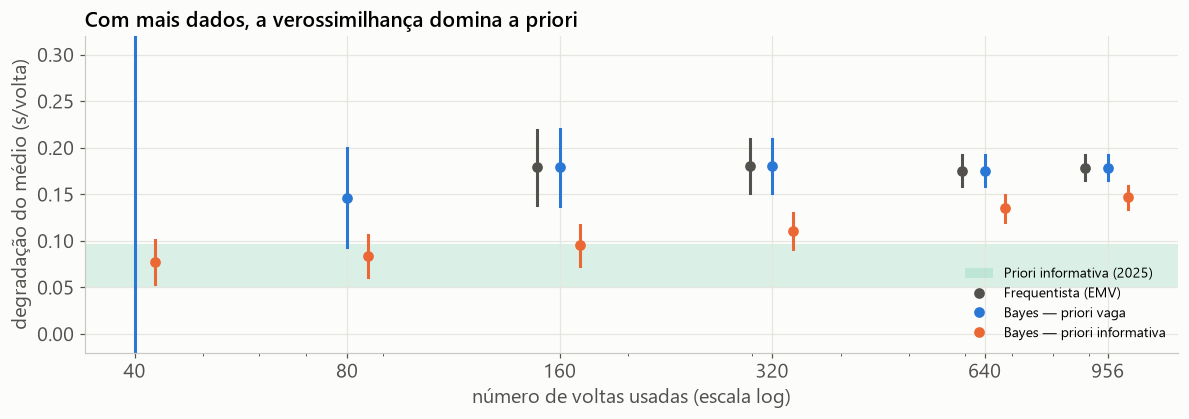

In [14]:
ordem = np.random.default_rng(SEMENTE).permutation(len(y26))
tamanhos = [40, 80, 160, 320, 640, len(y26)]
c_deg = vetor_c(nomes26, QOI["Degradação do médio (s por volta)"])
fig, ax = plt.subplots(figsize=(11, 4))
d_pri = stats.t(df=2 * pi.a, loc=c_deg @ pi.m, scale=np.sqrt(pi.b / pi.a * c_deg @ pi.V @ c_deg))
ax.axhspan(d_pri.ppf(0.025), d_pri.ppf(0.975), color=COR["priori"], alpha=0.15, lw=0, label=NOME_MET["priori"])
for n_sub in tamanhos:
    Xs, ys = X26[ordem[:n_sub]], y26[ordem[:n_sub]]
    res = {}
    if np.linalg.matrix_rank(Xs) == Xs.shape[1]:                # o EMV só existe se X tiver posto completo
        e = ajustar_emv(Xs, ys); ep = np.sqrt(c_deg @ e["cov"][:-1, :-1] @ c_deg)
        res["freq"] = (c_deg @ e["beta"], c_deg @ e["beta"] - 1.96 * ep, c_deg @ e["beta"] + 1.96 * ep)
    for k in ("vaga", "info"):
        d = t_exata(atualizar(prioris[k], Xs, ys), c_deg)
        res[k] = (d.mean(), d.ppf(0.025), d.ppf(0.975))
    for k, desl in (("freq", 0.93), ("vaga", 1.0), ("info", 1.07)):
        if k in res:
            m_, lo, hi = res[k]
            ax.plot([n_sub * desl] * 2, [lo, hi], color=COR[k], lw=2)
            ax.plot(n_sub * desl, m_, "o", color=COR[k], label=NOME_MET[k] if n_sub == tamanhos[-1] else None)
ax.set_xscale("log"); ax.set_xticks(tamanhos, [str(t) for t in tamanhos]); ax.set_ylim(-0.02, 0.32)
ax.set_xlabel("número de voltas usadas (escala log)"); ax.set_ylabel("degradação do médio (s/volta)")
ax.set_title("Com mais dados, a verossimilhança domina a priori"); ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); salvar(fig, "fig11_assintotico"); plt.show()

**Leitura.** Com 40 ou 80 voltas o EMV nem existe (com 38 coeficientes, $X^\top X$ fica singular), enquanto a posteriori existe sempre. A priori vaga dá intervalos enormes (fora da escala em n = 40), e a informativa fica presa ao valor de 2025. Com mais dados, a verossimilhança domina: EMV e Bayes vago coincidem e a posteriori informativa é "arrastada" na direção dos dados. Com todas as voltas, porém, ela ainda não alcança o valor de 2026.

---

## 5. Etapa D — Predição bayesiana

$$
p(y_{\text{novo}}\mid\mathbf y,X)=\int_\Theta p(y_{\text{novo}}\mid\mathbf x_{\text{novo}},\theta)\,p(\theta\mid\mathbf y,X)\,d\theta
\ \ \Longrightarrow\ \
y_{\text{novo}}\mid\mathbf y\sim t_{2a_n}\Big(\mathbf x_{\text{novo}}^\top\mathbf m_n,\ \tfrac{b_n}{a_n}\big(1+\mathbf x_{\text{novo}}^\top V_n\mathbf x_{\text{novo}}\big)\Big).
$$

Computacionalmente, para cada sorteio $(\beta^{(s)},\sigma^{2(s)})$ do Gibbs sorteamos $y_{\text{novo}}^{(s)}\sim\mathcal N(\mathbf x_{\text{novo}}^\top\beta^{(s)},\sigma^{2(s)})$: isso calcula a integral por Monte Carlo. Usamos o mesmo cenário da Etapa A.

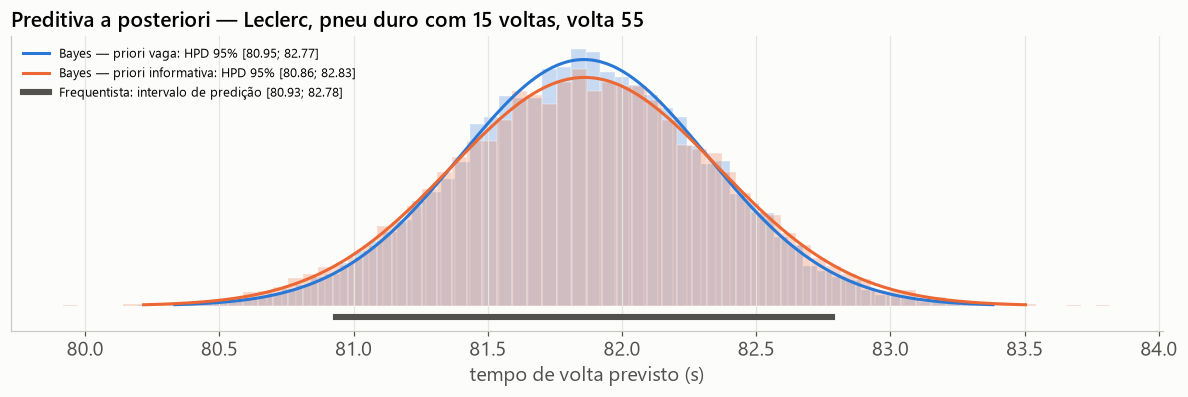

,media,lo,hi,mediana,media_exata
Frequentista (EMV),81.858,80.933,82.783,NaN,NaN
Bayes — priori vaga,81.855,80.953,82.768,81.858,81.858
Bayes — priori informativa,81.860,80.859,82.830,81.862,81.861


In [15]:
g = np.random.default_rng(SEMENTE + 7)
pred = {}
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, k in enumerate(("vaga", "info")):
    B, S2 = mcmc[k][0].reshape(-1, len(nomes26)), mcmc[k][1].ravel()
    y_mc = B @ x_novo + np.sqrt(S2) * g.standard_normal(len(S2))
    d_an = stats.t(df=2 * post[k].a, loc=x_novo @ post[k].m, scale=np.sqrt(post[k].b / post[k].a * (1 + x_novo @ post[k].V @ x_novo)))
    lo, hi = az.hdi(y_mc, prob=0.95)
    pred[k] = dict(media=y_mc.mean(), mediana=np.median(y_mc), lo=lo, hi=hi, media_exata=d_an.mean())
    grade = np.linspace(d_an.ppf(0.0005), d_an.ppf(0.9995), 300)
    ax.hist(y_mc, bins=70, density=True, color=COR[k], alpha=0.25, edgecolor=SUPERFICIE)
    ax.plot(grade, d_an.pdf(grade), color=COR[k], lw=2, label=f"{NOME_MET[k]}: HPD 95% [{lo:.2f}; {hi:.2f}]")
ax.plot([pred_freq["lo"], pred_freq["hi"]], [-0.04] * 2, color=COR["freq"], lw=4,
        label=f"Frequentista: intervalo de predição [{pred_freq['lo']:.2f}; {pred_freq['hi']:.2f}]")
ax.set_title("Preditiva a posteriori — Leclerc, pneu duro com 15 voltas, volta 55")
ax.set_xlabel("tempo de volta previsto (s)"); ax.set_yticks([]); ax.legend(fontsize=8.5, loc="upper left")
fig.tight_layout(); salvar(fig, "fig13_preditiva_cenario"); plt.show()
pd.DataFrame({NOME_MET["freq"]: pred_freq, **{NOME_MET[k]: pred[k] for k in pred}}).T.round(3)

**Leitura.** As três abordagens preveem **≈ 81,86 s**, com intervalos de 95% de cerca de ±0,9 s. A largura vem quase toda da variação natural de uma volta ($\sigma\approx0{,}46$ s), e pouco da incerteza nos parâmetros. A média de Monte Carlo bate com a média analítica.

---

## 6. Etapa E — Comparação e discussão

### 6.1 Estimativas lado a lado

In [16]:
def tabela_bayes(k):
    B, S2 = (m.reshape(-1, *m.shape[2:]) for m in mcmc[k])
    lin = {r: (x.mean(), *az.hdi(x, prob=0.95)) for r, x in amostras(B).items()}
    lin["Variância do ruído σ² (s²)"] = (S2.mean(), *az.hdi(S2, prob=0.95))
    return pd.DataFrame(lin, index=["media", "lo", "hi"]).T

bayes = {k: tabela_bayes(k) for k in ("vaga", "info")}
fmt = lambda d, r: f"{d.loc[r, 'media']:.3f} [{d.loc[r, 'lo']:.3f}; {d.loc[r, 'hi']:.3f}]"
pd.DataFrame({"EMV [IC 95%]": {r: fmt(freq, r) for r in freq.index},
              "Bayes vaga: média [HPD 95%]": {r: fmt(bayes["vaga"], r) for r in freq.index},
              "Bayes informativa: média [HPD 95%]": {r: fmt(bayes["info"], r) for r in freq.index}})

,EMV [IC 95%],Bayes vaga: média [HPD 95%],Bayes informativa: média [HPD 95%]
Degradação do médio (s por volta),0.179 [0.165; 0.192],0.179 [0.165; 0.192],0.147 [0.135; 0.159]
Degradação do macio (s por volta),0.212 [0.188; 0.236],0.212 [0.189; 0.237],0.158 [0.139; 0.177]
Degradação do duro (s por volta),0.140 [0.133; 0.148],0.140 [0.133; 0.148],0.140 [0.132; 0.148]
Macio novo − médio novo (s),-0.380 [-0.606; -0.153],-0.380 [-0.610; -0.160],-0.226 [-0.436; -0.028]
Duro novo − médio novo (s),0.218 [0.073; 0.363],0.218 [0.071; 0.362],-0.022 [-0.165; 0.123]
Efeito por volta de corrida (s por volta),-0.060 [-0.062; -0.058],-0.060 [-0.062; -0.058],-0.059 [-0.061; -0.057]
Variância do ruído σ² (s²),0.208 [0.189; 0.226],0.208 [0.190; 0.227],0.242 [0.221; 0.263]


**Leitura.** EMV e Bayes com priori vaga dão praticamente os mesmos números, como prevê a teoria assintótica (Bernstein–von Mises). Nos coeficientes, as diferenças na 3ª casa decimal são erro de Monte Carlo do HPD: a posteriori exata (uma $t$ de Student) dá o mesmo intervalo do EMV. Em $\sigma^2$, a pequena diferença é real: a posteriori de $\sigma^2$ é uma gama-inversa, levemente assimétrica à direita, e por isso o HPD fica um pouco acima do IC simétrico do EMV ($[0{,}190;\,0{,}227]$ contra $[0{,}189;\,0{,}226]$). A priori informativa puxa a degradação do médio de 0,18 para **0,15 s/volta** e a do macio de 0,21 para 0,16: ela "acredita" no valor de 2025 (0,07), que os dados de 2026 contradizem. **O regulamento novo mudou o comportamento do pneu, e a informação antiga ficou desatualizada.**

### 6.2 Ajuste global: AIC/BIC *vs.* WAIC/LOO-CV

Comparamos o modelo principal (M2) com versões mais simples: M0, em que todos os compostos degradam igual, e M1, sem degradação por carro. $\text{AIC}=-2\ell(\hat\theta)+2k$ e $\text{BIC}=-2\ell(\hat\theta)+k\log n$ usam só o ponto $\hat\theta$. Já $\text{WAIC}=-2\big(\text{lppd}-p_{\text{WAIC}}\big)$ e o LOO-CV (aproximado por *Pareto-smoothed importance sampling*) usam toda a posteriori. Menor é melhor em todos.

In [17]:
def waic(ll):
    lppd_i = special.logsumexp(ll, axis=0) - np.log(ll.shape[0])
    return -2 * (lppd_i.sum() - ll.var(axis=0, ddof=1).sum())

linhas = {}
for mod in ("M0", "M1", "M2"):
    Xm, nm = matriz_X(t26, mod, **NIVEIS[2026])
    X25m, nm25 = matriz_X(t25, mod, **NIVEIS[2025])
    e, k_par = ajustar_emv(Xm, y26), Xm.shape[1] + 1
    lin = {"AIC": -2 * e["loglik"] + 2 * k_par, "BIC": -2 * e["loglik"] + k_par * np.log(len(y26))}
    for k, pr in (("vaga", priori_vaga(len(nm))), ("info", priori_informativa(X25m, y25, nm25, nm))):
        Bm, S2m = gibbs(Xm, y26, pr)
        ll = stats.norm.logpdf(y26, loc=np.einsum("cdp,np->cdn", Bm[:, ::5], Xm), scale=np.sqrt(S2m[:, ::5])[..., None])
        loo = az.loo(az.from_dict({"posterior": {"sigma2": S2m[:, ::5]}, "log_likelihood": {"y": ll}, "observed_data": {"y": y26}}))
        lin[f"WAIC ({k})"], lin[f"LOO-CV ({k})"] = waic(ll.reshape(-1, len(y26))), -2 * loo.elpd
    linhas[mod] = lin
pd.DataFrame(linhas).round(1)

,M0,M1,M2
AIC,1394.9,1329.1,1287.7
BIC,1526.2,1470.1,1477.4
WAIC (vaga),1397.7,1332.1,1293.2
LOO-CV (vaga),1397.8,1332.4,1293.6
WAIC (info),1408.6,1383.4,1329.6
LOO-CV (info),1408.8,1383.6,1329.9


**Leitura.**
* AIC, WAIC e LOO-CV escolhem **M2**: degradação diferente por composto **e** por carro. Ou seja, com o mesmo pneu, carros diferentes degradam diferente.
* O **BIC** prefere M1. Sua penalidade por parâmetro ($\log n\approx6{,}9$) é bem maior que a do AIC (2): ele busca o modelo mais simples, enquanto AIC, WAIC e LOO buscam a melhor predição.
* Com priori vaga, WAIC e LOO ficam próximos do AIC, como esperado. Com a priori informativa, eles **pioram**: é mais uma evidência de que a informação de 2025 atrapalha a predição de 2026.

### 6.3 Intervalo de confiança *vs.* intervalo de credibilidade

| | IC 95% (frequentista) | HPD 95% (bayesiano) |
|---|---|---|
| O que é aleatório | o **intervalo**; $\beta_1$ é fixo | o **parâmetro** $\beta_1$; os dados são fixos |
| Interpretação correta | "95% dos intervalos construídos assim, em repetições da corrida, conteriam o verdadeiro $\beta_1$" | "Dados os tempos observados, há 95% de probabilidade de $\beta_1$ estar neste intervalo" |
| Usa informação prévia | não | sim, via $p(\theta)$ |

Com priori vaga e muitos dados os números coincidem, mas o significado não. Só o intervalo bayesiano permite dizer "há 95% de chance de a degradação do médio estar entre 0,165 e 0,192 s/volta", que é exatamente a frase que o engenheiro quer ouvir. O preço é declarar a priori, e este trabalho mostrou que ela precisa ser relevante: uma priori de outra era pode distorcer o resultado.

---

## 7. Conclusão

* Em Barcelona 2026 o pneu médio perdeu **≈ 0,18 s por volta**, cerca de **2,5 vezes** o de 2025 (macio ≈ 0,21; duro ≈ 0,14): o novo regulamento mudou a degradação.
* Com priori vaga, EMV e Bayes coincidem nos números, mas não na interpretação. A priori informativa de 2025 deslocou as estimativas e piorou WAIC/LOO, o que mostra que conhecimento prévio só ajuda quando continua relevante.
* O Gibbs convergiu ($\hat R\le1{,}001$, ESS > 18 000) e reproduziu a posteriori exata.

**Limitações:** degradação tratada como linear; erros com cauda direita (tráfego) e correlação entre voltas seguidas; dados de uma única corrida.

**Referências.** Gelman et al. (2013), *Bayesian Data Analysis*, 3ª ed. · Gelman & Rubin (1992), *Statistical Science* · Vehtari et al. (2021), *Bayesian Analysis* ($\hat R$) · Vehtari, Gelman & Gabry (2017), *Statistics and Computing* (LOO/WAIC) · Ibrahim & Chen (2000), *Statistical Science* (power prior) · OpenF1 (openf1.org).